# HMS — ten evaluations of four models

**Models:** VIPEEGNet · EfficientNetB0 · PRISM (with time-reversal TTA) · VIPEEGNet + PRISM blend.
**Rows:** the 6,350 EEG rows rated by ≥10 experts (the high-quality set; the blend exists only there).
Every prediction is out-of-fold, each model on its own original split; rows are matched by eeg_id + exact vote counts.
**Label for yes/no metrics:** the experts' majority class (ties → first class in the list order).
**CIs:** 95%, resampling whole patients (paired: the same resamples for every model).

| # | Evaluation | Question it answers | Main numbers |
|---|---|---|---|
| 1 | Distribution fit | How close are the probabilities to the experts' vote shares? | KLD (competition metric), Jensen–Shannon, cross-entropy, total variation; paired difference vs VIPEEGNet |
| 2 | False positives / false negatives per class | Which classes does it over-call or miss? | TP, FP, FN, TN, sensitivity, specificity, PPV, NPV, F1 |
| 3 | Threshold-free discrimination | How well does it rank each class, at any threshold? | AUROC and AUPRC (better for rare classes) with CIs |
| 4 | Clinical decision tasks | Does it get the decisions a neurologist makes right? | Seizure vs not · harmful pattern vs Other · periodic vs rhythmic · lateralized vs generalized |
| 5 | Error types | When wrong, how bad is the mistake? | Missed seizures, false seizure alarms, harmful called Other, wrong side, PD↔RDA, per 1,000 EEGs |
| 6 | Fixed operating points | What happens at a clinically set alarm threshold? | Sensitivity at 95% specificity, specificity at 90% sensitivity, false alarms per 100 EEGs |
| 7 | Calibration and uncertainty | Can its confidence be trusted, and used to defer cases? | Class-wise and top-label ECE, overconfidence, Brier, accuracy when deferring the least-confident cases |
| 8 | Model vs expert raters | Is it as good as one more expert? | Agreement with the majority of the *other* experts (the same test experts face), Cohen's κ, top-2 accuracy |
| 9 | Difficulty and ambiguity | Does it fail where experts disagree, and does it know? | Scores by expert-agreement level and vote count; correlation of model and expert uncertainty |
| 10 | Robustness and complementarity | Is it stable across folds and patients, and do models fail on the same EEGs? | Fold spread, worst-patient KLD, McNemar test, both-wrong rate |

Outputs go to `results/comparisons/top10_eval/`: one CSV per evaluation, six figures, `scorecard.csv`, `report.md`.

In [1]:
PROJECT_DIR = '~/hms'
MODELS = [                                          # [archive tag, display name]; the first one is the reference
    ['vipeegnet_groupkfold_v1', 'VIPEEGNet'],
    ['effnetb0_native_v1',      'EfficientNetB0'],
    ['prism_wf5_tta_v1',        'PRISM'],
    ['blend_vip_prism_wf5_v1',  'VIPEEGNet + PRISM'],
]
N_BOOT = 2000          # patient resamples for KLD-type metrics
N_BOOT_AUC = 300       # patient resamples for AUROC / AUPRC (slower)
OUT_NAME = 'top10_eval'

In [2]:
# Parameters
PROJECT_DIR = "/home/nfs/jhb-dehzangi/ws04/gs1147/hms"


In [3]:
import os, sys, json, numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.stats import spearmanr, binomtest
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix, cohen_kappa_score, f1_score
P = os.path.abspath(os.path.expanduser(PROJECT_DIR))
sys.path.insert(0, f'{P}/results'); os.environ['HMS_RESULTS'] = f'{P}/results'
from load_results import load_oof
CLASS = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']
SZ, LPD, GPD, LRDA, GRDA, OTH = range(6)
OUTD = f'{P}/results/comparisons/{OUT_NAME}'; os.makedirs(OUTD, exist_ok=True)
pid = pd.read_csv(f'{P}/hms-data/train.csv', usecols=['eeg_id', 'patient_id']).groupby('eeg_id').patient_id.first()
NAMES = [n for _, n in MODELS]; REF = NAMES[0]
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

# chart style: fixed colour per model (validated categorical palette), recessive axes, ink-coloured text
COL = dict(zip(NAMES, ['#2a78d6', '#eb6834', '#1baf7a', '#e87ba4', '#6250d6', '#eda100']))
SURF, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'font.size': 10,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False})
def save(fig, name):
    fig.savefig(f'{OUTD}/{name}', dpi=150); plt.close(fig); display(Image(f'{OUTD}/{name}'))
def legend_below(fig, ax, n):
    fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=n, fontsize=9)

def keyed(tag):
    yt, yp, m = load_oof(tag, 'hq')
    v = np.rint(yt * m.votes.values[:, None]).astype(int)
    m['key'] = m.eeg_id.astype(str) + ':' + pd.Series([','.join(map(str, r)) for r in v]).values
    assert m.key.is_unique, f'{tag}: duplicate row keys'
    return yt, yp, m

base = None; preds, folds = {}, {}
for tag, name in MODELS:
    yt_, yp_, m_ = keyed(tag)
    if base is None:
        base = (yt_, m_.reset_index(drop=True)); order = np.arange(len(m_))
    else:
        assert set(m_.key) == set(base[1].key), f'{name} was scored on different rows than {REF}'
        order = pd.Series(np.arange(len(m_)), index=m_.key)[base[1].key].values
        assert np.allclose(yt_[order], base[0], atol=1e-5), f'{name}: labels differ'
    p = np.clip(yp_[order], 1e-7, 1); preds[name] = p / p.sum(1, keepdims=True)
    folds[name] = m_.fold.values[order]
yt, meta = base
VOTES = np.rint(yt * meta.votes.values[:, None]).astype(int); NV = VOTES.sum(1)
meta['patient_id'] = meta.eeg_id.map(pid).values
Y = yt.argmax(1)                                   # majority class (ties -> first)
N = len(yt); OH = (Y[:, None] == np.arange(6)).astype(int)
pats, inv = np.unique(meta.patient_id.values, return_inverse=True); NP = len(pats); CNT = np.bincount(inv)
rng = np.random.default_rng(0)
BS = rng.integers(0, NP, (N_BOOT, NP))
PAT_ROWS = [np.where(inv == j)[0] for j in range(NP)]
BS_ROWS = [np.concatenate([PAT_ROWS[j] for j in s]) for s in rng.integers(0, NP, (N_BOOT_AUC, NP))]
def boot_mean(x):                                  # patient-resampled means of a per-row quantity
    s = np.bincount(inv, x); return s[BS].sum(1) / CNT[BS].sum(1)
def ci(b): return np.percentile(b, 2.5), np.percentile(b, 97.5)
def kld(t, p): t = np.clip(t, 1e-7, 1); return (t * np.log(t / p)).sum(1)
PRED = {n: p.argmax(1) for n, p in preds.items()}
RIGHT = {n: (PRED[n] == Y) for n in NAMES}
SCORE = {}                                         # headline number per evaluation -> scorecard
print(f'{N:,} rows | {NP:,} patients | majority-class counts:', dict(zip(CLASS, OH.sum(0))))

6,350 rows | 1,063 patients | majority-class counts: {'Seizure': 279, 'LPD': 1295, 'GPD': 806, 'LRDA': 361, 'GRDA': 447, 'Other': 3162}


## 1. Distribution fit — how close are the probabilities to the vote shares?

In [4]:
def jsd(t, p):
    m = (t + p) / 2; t_ = np.clip(t, 1e-7, 1); m = np.clip(m, 1e-7, 1)
    return 0.5 * (t_ * np.log(t_ / m)).sum(1) + 0.5 * (p * np.log(p / m)).sum(1)
METRICS = {'KLD': kld, 'Jensen-Shannon': jsd,
           'cross-entropy': lambda t, p: -(t * np.log(p)).sum(1),
           'total variation': lambda t, p: 0.5 * np.abs(t - p).sum(1)}
K = {n: kld(yt, p) for n, p in preds.items()}
rows = []
for n, p in preds.items():
    r = {'model': n}
    for mname, f in METRICS.items():
        x = f(yt, p); lo, hi = ci(boot_mean(x)); r[mname] = x.mean(); r[f'{mname} CI'] = f'{lo:.4f}-{hi:.4f}'
    d = boot_mean(K[n] - K[REF]); lo, hi = ci(d)
    r[f'KLD vs {REF}'] = (K[n] - K[REF]).mean(); r['diff CI'] = f'{lo:+.4f} to {hi:+.4f}'
    r['P(better than ref)'] = (d < 0).mean()
    rows.append(r)
E1 = pd.DataFrame(rows).set_index('model'); E1.to_csv(f'{OUTD}/e1_distribution_fit.csv')
SCORE['1 KLD (lower better)'] = E1.KLD
E1.round(4)

,KLD,KLD CI,Jensen-Shannon,Jensen-Shannon CI,cross-entropy,cross-entropy CI,total variation,total variation CI,KLD vs VIPEEGNet,diff CI,P(better than ref)
model,,,,,,,,,,,
VIPEEGNet,0.2217,0.2117-0.2316,0.0565,0.0542-0.0586,0.8751,0.8370-0.9128,0.1949,0.1872-0.2019,0.0000,+0.0000 to +0.0000,0.0
EfficientNetB0,0.4648,0.4391-0.4911,0.1067,0.1015-0.1117,1.1182,1.0700-1.1699,0.2929,0.2808-0.3045,0.2431,+0.2188 to +0.2664,0.0
PRISM,0.2732,0.2587-0.2877,0.0672,0.0642-0.0700,0.9267,0.8840-0.9686,0.2193,0.2101-0.2279,0.0516,+0.0415 to +0.0635,0.0
VIPEEGNet + PRISM,0.2177,0.2075-0.2274,0.0556,0.0534-0.0577,0.8711,0.8326-0.9095,0.1932,0.1856-0.2002,-0.0040,-0.0056 to -0.0023,1.0


## 2. False positives and false negatives per class (top prediction vs majority vote)

In [5]:
rows = []; cms = {}
for n in NAMES:
    cm = confusion_matrix(Y, PRED[n], labels=range(6)); cms[n] = cm
    pd.DataFrame(cm, index=[f'true {c}' for c in CLASS], columns=[f'pred {c}' for c in CLASS]).to_csv(
        f'{OUTD}/e2_confusion_counts_{n.replace(" ", "_").replace("+", "plus")}.csv')
    for c in range(6):
        TP = cm[c, c]; FN = cm[c].sum() - TP; FP = cm[:, c].sum() - TP; TN = N - TP - FN - FP
        sens = TP / (TP + FN); spec = TN / (TN + FP); ppv = TP / max(TP + FP, 1); npv = TN / max(TN + FN, 1)
        rows.append({'model': n, 'class': CLASS[c], 'n (majority)': TP + FN, 'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN,
                     'sensitivity %': sens * 100, 'specificity %': spec * 100, 'PPV %': ppv * 100, 'NPV %': npv * 100,
                     'F1 %': 2 * ppv * sens / max(ppv + sens, 1e-9) * 100,
                     'FP per 100 EEGs': FP / N * 100, 'FN per 100 EEGs': FN / N * 100})
E2 = pd.DataFrame(rows); E2.to_csv(f'{OUTD}/e2_fp_fn_per_class.csv', index=False)
SCORE['2 macro-F1 % (higher better)'] = pd.Series({n: f1_score(Y, PRED[n], average='macro') * 100 for n in NAMES})
for col in ('FP', 'FN', 'sensitivity %', 'specificity %', 'PPV %', 'NPV %', 'F1 %'):
    print(col); display(E2.pivot(index='class', columns='model', values=col).loc[CLASS, NAMES].round(1))

FP


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,74,563,101,73
LPD,275,231,224,253
GPD,160,231,139,143
LRDA,113,143,107,87
GRDA,97,340,145,98
Other,726,566,883,755


FN


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,122,52,130,120
LPD,300,470,375,312
GPD,181,239,237,186
LRDA,223,282,258,224
GRDA,261,213,249,256
Other,358,818,350,311


sensitivity %


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,56.3,81.4,53.4,57.0
LPD,76.8,63.7,71.0,75.9
GPD,77.5,70.3,70.6,76.9
LRDA,38.2,21.9,28.5,38.0
GRDA,41.6,52.3,44.3,42.7
Other,88.7,74.1,88.9,90.2


... (4 outputs left out)

NPV %


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,98.0,99.1,97.9,98.0
LPD,94.1,91.1,92.8,93.9
GPD,96.7,95.7,95.8,96.7
LRDA,96.3,95.4,95.8,96.3
GRDA,95.7,96.3,95.9,95.8
Other,87.3,76.2,86.8,88.7


F1 %


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,61.6,42.5,56.3,62.2
LPD,77.6,70.2,75.4,77.7
GPD,78.6,70.7,75.2,79.0
LRDA,45.1,27.1,36.1,46.8
GRDA,51.0,45.8,50.1,51.9
Other,83.8,77.2,82.0,84.2


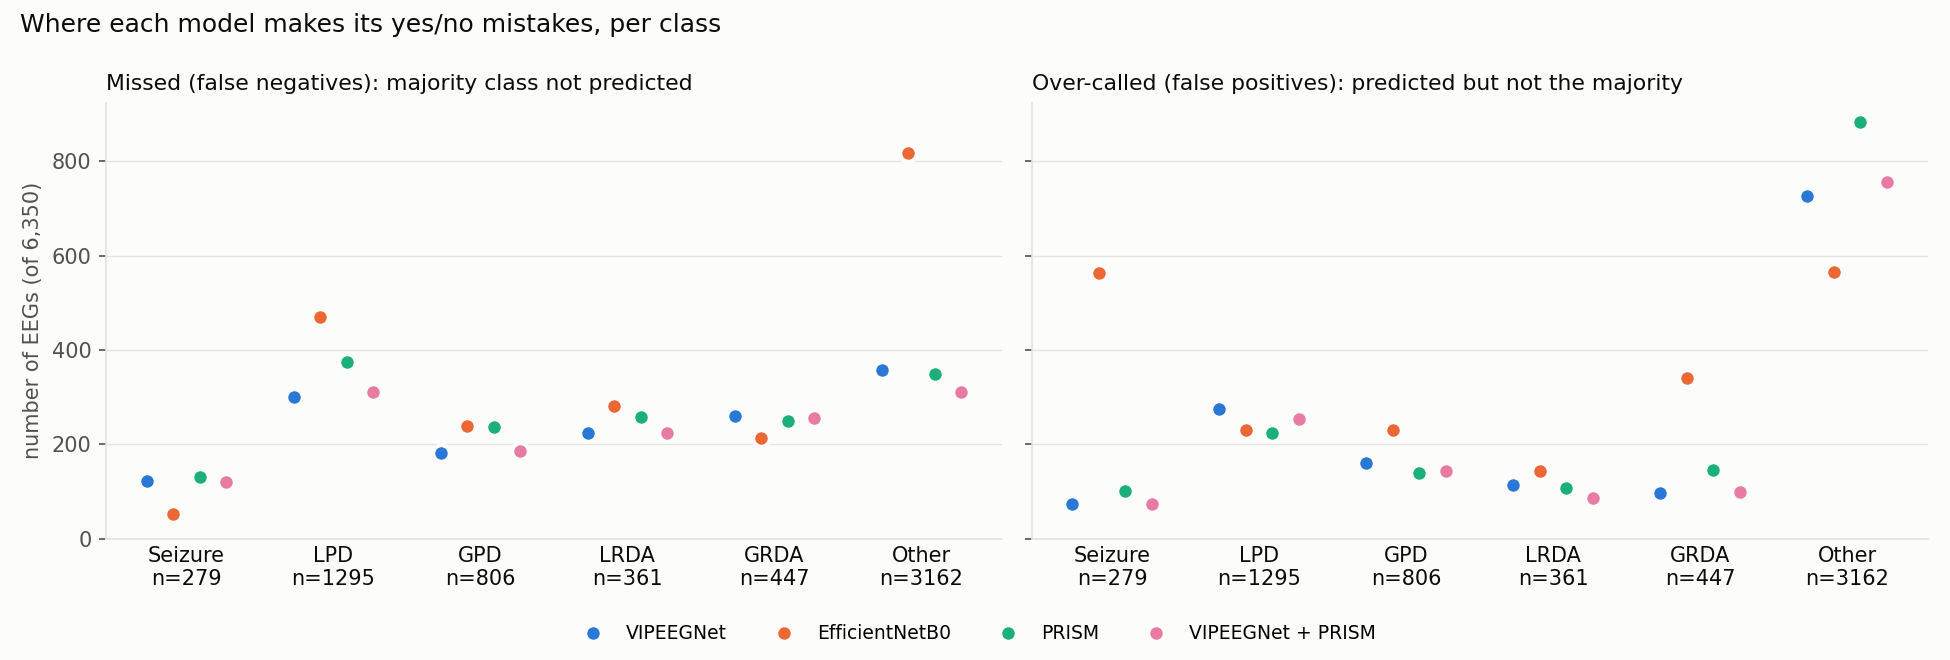

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
x = np.arange(6); off = np.linspace(-0.27, 0.27, len(NAMES))
for ax, col, title in ((axs[0], 'FN', 'Missed (false negatives): majority class not predicted'),
                       (axs[1], 'FP', 'Over-called (false positives): predicted but not the majority')):
    piv = E2.pivot(index='class', columns='model', values=col).loc[CLASS]
    for o, n in zip(off, NAMES):
        ax.plot(x + o, piv[n].values, 'o', ms=8, color=COL[n], mec=SURF, mew=2, label=n)
    ax.set_xticks(x, [f'{c}\nn={OH[:, i].sum()}' for i, c in enumerate(CLASS)]); ax.tick_params(axis='x', colors=INK, length=0)
    ax.set_title(title, loc='left', fontsize=10.5, color=INK); ax.grid(axis='x', visible=False)
axs[0].set_ylabel(f'number of EEGs (of {N:,})'); axs[0].set_ylim(bottom=0)
fig.suptitle('Where each model makes its yes/no mistakes, per class', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(NAMES)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig1_fp_fn.png')

## 3. Threshold-free discrimination — AUROC and AUPRC per class

In [7]:
rows = []
for n, p in preds.items():
    for c in range(6):
        y, s = OH[:, c], p[:, c]
        ba = [roc_auc_score(y[r], s[r]) for r in BS_ROWS]; bp = [average_precision_score(y[r], s[r]) for r in BS_ROWS]
        rows.append({'model': n, 'class': CLASS[c], 'prevalence %': y.mean() * 100,
                     'AUROC': roc_auc_score(y, s), 'AUROC CI': '%.3f-%.3f' % ci(ba),
                     'AUPRC': average_precision_score(y, s), 'AUPRC CI': '%.3f-%.3f' % ci(bp)})
E3 = pd.DataFrame(rows); E3.to_csv(f'{OUTD}/e3_auroc_auprc.csv', index=False)
SCORE['3 macro-AUPRC (higher better)'] = E3.groupby('model').AUPRC.mean()
for col in ('AUROC', 'AUPRC'):
    t = E3.pivot(index='class', columns='model', values=col).loc[CLASS, NAMES]; t.loc['macro'] = t.mean()
    print(col, '(chance level for AUPRC = prevalence)'); display(t.round(3))

AUROC (chance level for AUPRC = prevalence)


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,0.975,0.937,0.965,0.976
LPD,0.963,0.918,0.957,0.965
GPD,0.976,0.950,0.970,0.977
LRDA,0.943,0.850,0.920,0.944
GRDA,0.952,0.907,0.941,0.954
Other,0.929,0.874,0.912,0.931
macro,0.956,0.906,0.944,0.957


AUPRC (chance level for AUPRC = prevalence)


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,
Seizure,0.722,0.408,0.575,0.728
LPD,0.878,0.781,0.854,0.880
GPD,0.877,0.756,0.847,0.879
LRDA,0.536,0.278,0.450,0.545
GRDA,0.610,0.457,0.544,0.616
Other,0.931,0.881,0.916,0.933
macro,0.759,0.594,0.698,0.763


## 4. Clinical decision tasks
- **Seizure vs not** — score P(Seizure); decision = top prediction is Seizure.
- **Harmful vs Other** — any of the five IIIC patterns vs "Other"; score 1 − P(Other); decision = top prediction is not Other. A false negative = harmful activity reported as normal/other.
- **Periodic vs rhythmic** and **lateralized vs generalized** — only on EEGs whose majority is LPD, GPD, LRDA or GRDA; scores renormalised over those four classes; decision = score > 0.5.

In [8]:
IIIC4 = [LPD, GPD, LRDA, GRDA]
def tasks(p):
    s4 = p[:, IIIC4].sum(1); sub = np.isin(Y, IIIC4)
    return {
        'Seizure vs not':             (np.ones(N, bool), Y == SZ, p[:, SZ], p.argmax(1) == SZ),
        'Harmful vs Other':           (np.ones(N, bool), Y != OTH, 1 - p[:, OTH], p.argmax(1) != OTH),
        'Periodic vs rhythmic':       (sub, np.isin(Y, [LPD, GPD]), (p[:, LPD] + p[:, GPD]) / s4, None),
        'Lateralized vs generalized': (sub, np.isin(Y, [LPD, LRDA]), (p[:, LPD] + p[:, LRDA]) / s4, None),
    }
rows = []
for n, p in preds.items():
    for t, (m, y, s, dec) in tasks(p).items():
        y, s = y[m], s[m]; d = (s > 0.5) if dec is None else dec[m]
        TP = (d & y).sum(); FN = (~d & y).sum(); FP = (d & ~y).sum(); TN = (~d & ~y).sum()
        rows.append({'model': n, 'task': t, 'n': int(m.sum()), 'positives': int(y.sum()), 'AUROC': roc_auc_score(y, s),
                     'sensitivity %': TP / (TP + FN) * 100, 'specificity %': TN / (TN + FP) * 100,
                     'PPV %': TP / max(TP + FP, 1) * 100, 'NPV %': TN / max(TN + FN, 1) * 100,
                     'false negatives': int(FN), 'false positives': int(FP)})
E4 = pd.DataFrame(rows); E4.to_csv(f'{OUTD}/e4_clinical_tasks.csv', index=False)
SCORE['4 harmful-vs-Other AUROC (higher better)'] = E4[E4.task == 'Harmful vs Other'].set_index('model')['AUROC']
for t in E4.task.unique():
    print(t); display(E4[E4.task == t].drop(columns='task').set_index('model').loc[NAMES].round(3))

Seizure vs not


,n,positives,AUROC,sensitivity %,specificity %,PPV %,NPV %,false negatives,false positives
model,,,,,,,,,
VIPEEGNet,6350,279,0.975,56.272,98.781,67.965,98.006,122,74
EfficientNetB0,6350,279,0.937,81.362,90.726,28.734,99.065,52,563
PRISM,6350,279,0.965,53.405,98.336,59.600,97.869,130,101
VIPEEGNet + PRISM,6350,279,0.976,56.989,98.798,68.534,98.039,120,73


Harmful vs Other


,n,positives,AUROC,sensitivity %,specificity %,PPV %,NPV %,false negatives,false positives
model,,,,,,,,,
VIPEEGNet,6350,3188,0.929,77.227,88.678,87.305,79.433,726,358
EfficientNetB0,6350,3188,0.874,82.246,74.130,76.221,80.550,566,818
PRISM,6350,3188,0.912,72.302,88.931,86.817,76.103,883,350
VIPEEGNet + PRISM,6350,3188,0.931,76.317,90.164,88.666,79.063,755,311


Periodic vs rhythmic


,n,positives,AUROC,sensitivity %,specificity %,PPV %,NPV %,false negatives,false positives
model,,,,,,,,,
VIPEEGNet,2909,2101,0.970,94.622,81.064,92.854,85.286,113,153
EfficientNetB0,2909,2101,0.946,91.766,80.569,92.470,79.005,173,157
PRISM,2909,2101,0.964,91.671,86.634,94.690,80.000,175,108
VIPEEGNet + PRISM,2909,2101,0.971,94.384,82.921,93.494,85.025,118,138


Lateralized vs generalized


,n,positives,AUROC,sensitivity %,specificity %,PPV %,NPV %,false negatives,false positives
model,,,,,,,,,
VIPEEGNet,2909,1656,0.986,94.988,92.977,94.702,93.349,83,88
EfficientNetB0,2909,1656,0.935,85.024,88.348,90.605,81.697,248,146
PRISM,2909,1656,0.977,92.814,92.179,94.006,90.659,119,98
VIPEEGNet + PRISM,2909,1656,0.986,94.867,93.536,95.097,93.238,85,81


## 5. Error types — when the top prediction is wrong, what kind of mistake is it?

In [9]:
FAM = {LPD: 'PD', GPD: 'PD', LRDA: 'RDA', GRDA: 'RDA'}
TYPES = ['missed seizure', 'false seizure alarm', 'harmful pattern called Other', 'Other called a harmful pattern',
         'right pattern, wrong side (L vs G)', 'periodic vs rhythmic mix-up']
def err_type(t, q):
    if t == q: return None
    if t == SZ: return TYPES[0]
    if q == SZ: return TYPES[1]
    if q == OTH: return TYPES[2]
    if t == OTH: return TYPES[3]
    return TYPES[4] if FAM[t] == FAM[q] else TYPES[5]
rows = []
for n in NAMES:
    et = pd.Series([err_type(t, q) for t, q in zip(Y, PRED[n])])
    vc = et.value_counts()
    for k in TYPES: rows.append({'model': n, 'error type': k, 'count': int(vc.get(k, 0)), 'per 1,000 EEGs': vc.get(k, 0) / N * 1000})
    rows.append({'model': n, 'error type': 'all errors', 'count': int(et.notna().sum()), 'per 1,000 EEGs': et.notna().mean() * 1000})
E5 = pd.DataFrame(rows); E5.to_csv(f'{OUTD}/e5_error_types.csv', index=False)
SCORE['5 errors per 1,000 EEGs (lower better)'] = E5[E5['error type'] == 'all errors'].set_index('model')['per 1,000 EEGs']
SCORE['5b seizure errors per 1,000 EEGs, missed + false alarms (lower better)'] = E5[E5['error type'].isin(TYPES[:2])].groupby('model')['per 1,000 EEGs'].sum()
display(E5.pivot(index='error type', columns='model', values='per 1,000 EEGs').loc[TYPES + ['all errors'], NAMES].round(1))

model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
error type,,,,
missed seizure,19.2,8.2,20.5,18.9
false seizure alarm,11.7,88.7,15.9,11.5
harmful pattern called Other,107.7,86.1,131.7,112.6
Other called a harmful pattern,52.3,86.6,47.6,44.9
"right pattern, wrong side (L vs G)",13.5,34.0,16.9,13.4
periodic vs rhythmic mix-up,23.1,23.0,19.4,20.6
all errors,227.6,326.6,251.8,221.9


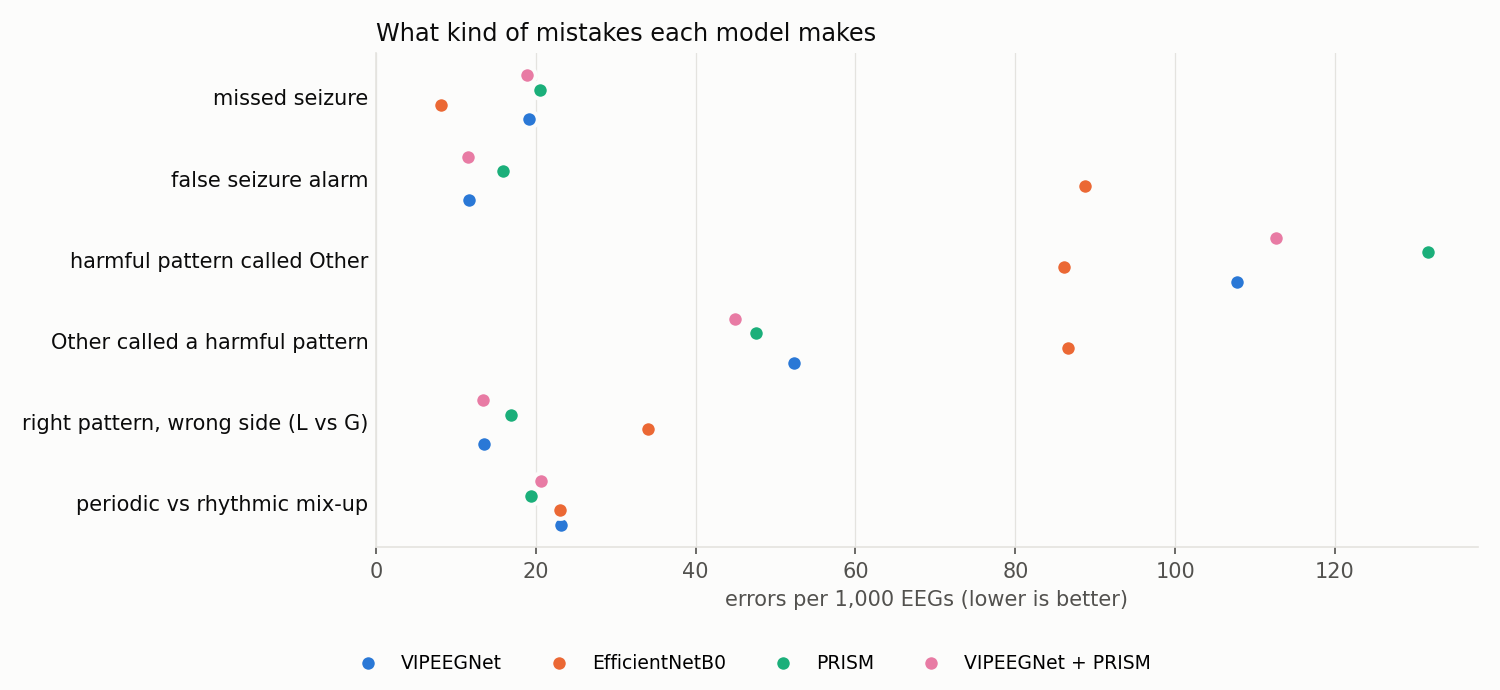

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.6))
piv = E5.pivot(index='error type', columns='model', values='per 1,000 EEGs').loc[TYPES[::-1]]
yy = np.arange(len(TYPES)); off = np.linspace(-0.27, 0.27, len(NAMES))
for o, n in zip(off, NAMES):
    ax.plot(piv[n].values, yy + o, 'o', ms=8, color=COL[n], mec=SURF, mew=2, label=n)
ax.set_yticks(yy, piv.index); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
ax.set_xlabel('errors per 1,000 EEGs (lower is better)'); ax.set_xlim(left=0)
ax.set_title('What kind of mistakes each model makes', loc='left', fontsize=11.5, color=INK)
legend_below(fig, ax, len(NAMES)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig2_error_types.png')

## 6. Fixed operating points — what a clinical alarm threshold would give

In [11]:
def op_points(y, s):
    fpr, tpr, thr = roc_curve(y, s); Pn, Nn = y.sum(), (1 - y).sum()
    i95 = np.where(fpr <= 0.05)[0][-1]                       # best sensitivity with specificity >= 95%
    i90 = np.where(tpr >= 0.90)[0][0]                        # best specificity with sensitivity >= 90%
    tp, fp = tpr[i90] * Pn, fpr[i90] * Nn
    return {'sensitivity % at 95% specificity': tpr[i95] * 100, 'specificity % at 90% sensitivity': (1 - fpr[i90]) * 100,
            'PPV % at 90% sensitivity': tp / max(tp + fp, 1e-9) * 100,
            'false alarms per 100 EEGs at 90% sensitivity': fp / len(y) * 100, 'threshold for 90% sensitivity': thr[i90]}
rows = []
for n, p in preds.items():
    for c in range(6): rows.append({'model': n, 'target': CLASS[c], **op_points(OH[:, c], p[:, c])})
    rows.append({'model': n, 'target': 'Harmful (any IIIC)', **op_points((Y != OTH).astype(int), 1 - p[:, OTH])})
E6 = pd.DataFrame(rows); E6.to_csv(f'{OUTD}/e6_operating_points.csv', index=False)
SCORE['6 seizure specificity % at 90% sensitivity (higher better)'] = E6[E6.target == 'Seizure'].set_index('model')['specificity % at 90% sensitivity']
for col in ('sensitivity % at 95% specificity', 'specificity % at 90% sensitivity', 'false alarms per 100 EEGs at 90% sensitivity'):
    print(col); display(E6.pivot(index='target', columns='model', values=col).loc[CLASS + ['Harmful (any IIIC)'], NAMES].round(1))

sensitivity % at 95% specificity


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
target,,,,
Seizure,86.0,60.6,81.7,86.4
LPD,76.1,66.8,71.7,76.4
GPD,86.5,74.7,83.0,87.1
LRDA,65.1,36.6,53.5,64.3
GRDA,66.2,49.2,60.6,68.5
Other,67.5,54.0,63.3,67.7
Harmful (any IIIC),66.1,44.8,59.5,65.9


specificity % at 90% sensitivity


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
target,,,,
Seizure,92.9,85.9,90.8,93.3
LPD,89.7,72.6,87.8,90.5
GPD,93.4,86.3,91.0,93.6
LRDA,84.6,64.8,80.8,84.9
GRDA,88.8,76.6,84.9,88.6
Other,76.3,60.5,72.4,77.3
Harmful (any IIIC),76.3,66.5,73.0,77.3


false alarms per 100 EEGs at 90% sensitivity


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
target,,,,
Seizure,6.8,13.5,8.8,6.4
LPD,8.2,21.8,9.7,7.6
GPD,5.7,12.0,7.9,5.6
LRDA,14.5,33.2,18.1,14.2
GRDA,10.4,21.7,14.1,10.6
Other,11.9,19.8,13.9,11.4
Harmful (any IIIC),11.8,16.7,13.5,11.3


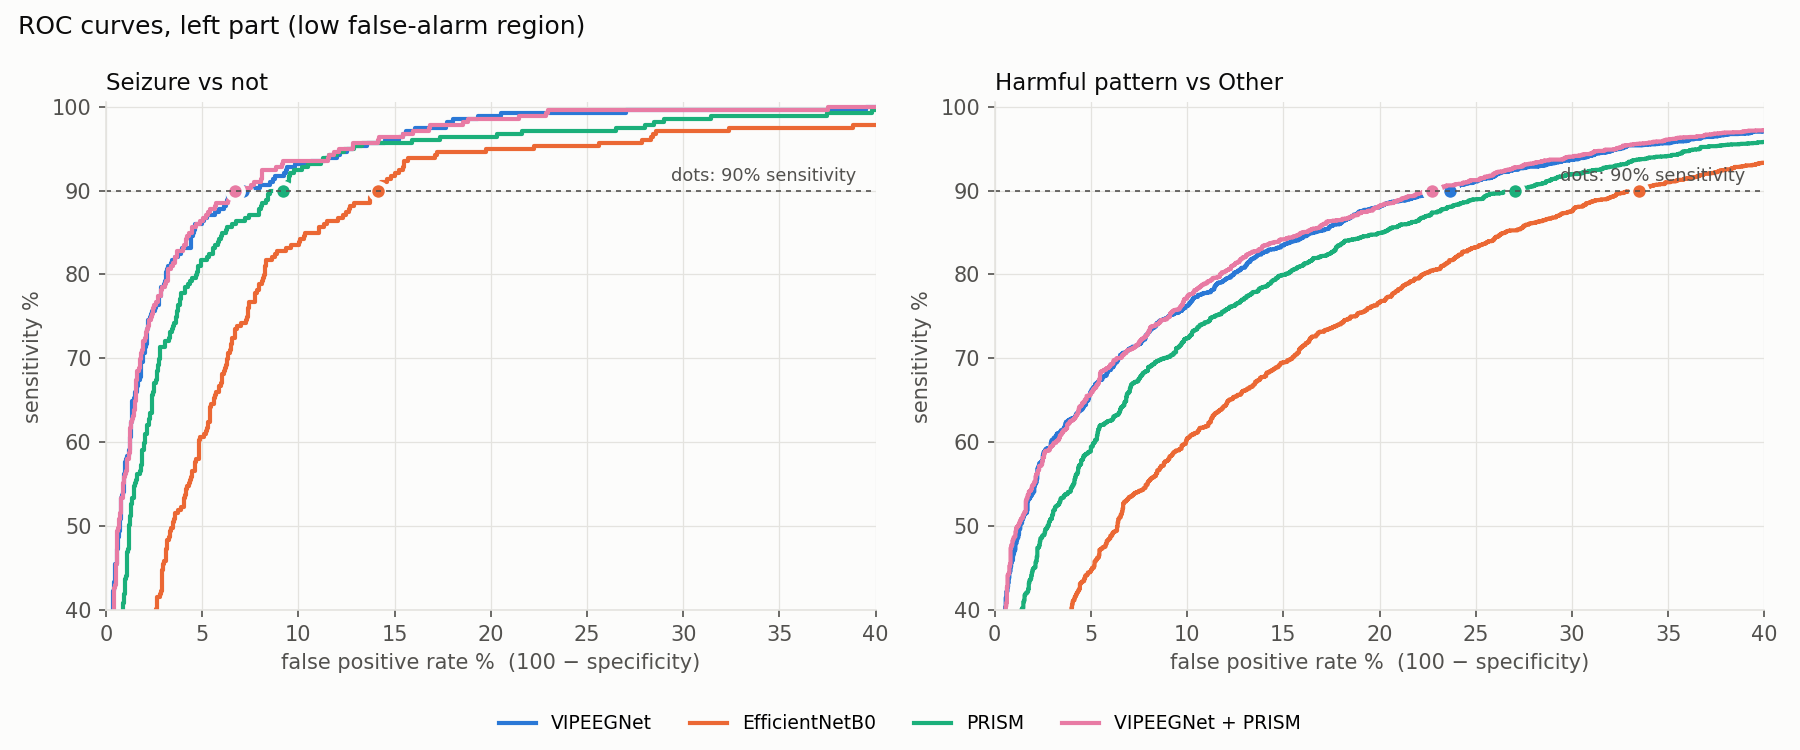

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, y, sfun) in zip(axs, (('Seizure vs not', OH[:, SZ], lambda p: p[:, SZ]),
                                     ('Harmful pattern vs Other', (Y != OTH).astype(int), lambda p: 1 - p[:, OTH]))):
    for n, p in preds.items():
        fpr, tpr, _ = roc_curve(y, sfun(p)); ax.plot(fpr * 100, tpr * 100, lw=2, color=COL[n], label=n)
        i = np.where(tpr >= 0.90)[0][0]; ax.plot(fpr[i] * 100, 90, 'o', ms=8, color=COL[n], mec=SURF, mew=2)
    ax.axhline(90, color=INK2, lw=0.8, ls=(0, (3, 3)))
    ax.text(39, 91.2, 'dots: 90% sensitivity', ha='right', fontsize=8.5, color=INK2)
    ax.set_xlim(0, 40); ax.set_ylim(40, 100.5)
    ax.set_xlabel('false positive rate %  (100 − specificity)'); ax.set_ylabel('sensitivity %')
    ax.set_title(title, loc='left', fontsize=11, color=INK)
fig.suptitle('ROC curves, left part (low false-alarm region)', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(NAMES)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig3_roc_operating_points.png')

## 7. Calibration and uncertainty
- **Class-wise ECE:** predicted probability vs expert vote share, per class, 15 bins.
- **Top-label ECE:** confidence of the top prediction vs how often it matches the majority.
- **Overconfidence:** mean (confidence − correct); positive = more confident than it should be.
- **Selective prediction:** keep the most confident X% of EEGs, defer the rest to a neurologist — accuracy and KLD on what is kept. AURC = area under the risk–coverage curve (lower is better).

In [13]:
def ece_classwise(p, bins=15):
    e = 0
    for c in range(6):
        idx = np.minimum((p[:, c] * bins).astype(int), bins - 1)
        e += np.abs(np.bincount(idx, p[:, c], bins) - np.bincount(idx, yt[:, c], bins)).sum() / N
    return e / 6
def ece_top(p, bins=15):
    conf = p.max(1); ok = (p.argmax(1) == Y).astype(float); idx = np.minimum((conf * bins).astype(int), bins - 1)
    return np.abs(np.bincount(idx, conf, bins) - np.bincount(idx, ok, bins)).sum() / N
COVER = [100, 90, 80, 70, 60, 50]
rows, cov_rows = [], []
for n, p in preds.items():
    conf = p.max(1); ok = RIGHT[n].astype(float); o = np.argsort(-conf, kind='stable')
    risk = 1 - np.cumsum(ok[o]) / np.arange(1, N + 1)
    rows.append({'model': n, 'class-wise ECE': ece_classwise(p), 'top-label ECE': ece_top(p),
                 'overconfidence (conf - acc)': (conf - ok).mean(), 'mean confidence': conf.mean(),
                 'accuracy %': ok.mean() * 100, 'Brier (vs vote shares)': ((p - yt) ** 2).sum(1).mean(), 'AURC': risk.mean()})
    for cv in COVER:
        keep = o[:int(round(N * cv / 100))]
        cov_rows.append({'model': n, 'coverage %': cv, 'accuracy %': ok[keep].mean() * 100, 'KLD': K[n][keep].mean()})
E7 = pd.DataFrame(rows).set_index('model'); E7.loc['(experts: mean top vote share)', 'mean confidence'] = yt.max(1).mean()
E7c = pd.DataFrame(cov_rows)
E7.to_csv(f'{OUTD}/e7_calibration.csv'); E7c.to_csv(f'{OUTD}/e7_selective_prediction.csv', index=False)
SCORE['7 class-wise ECE vs vote shares (lower better)'] = E7.loc[NAMES, 'class-wise ECE']
display(E7.round(4))
print('Accuracy % when deferring the least-confident EEGs'); display(E7c.pivot(index='coverage %', columns='model', values='accuracy %')[NAMES].sort_index(ascending=False).round(1))
print('KLD on the kept EEGs'); display(E7c.pivot(index='coverage %', columns='model', values='KLD')[NAMES].sort_index(ascending=False).round(4))

,class-wise ECE,top-label ECE,overconfidence (conf - acc),mean confidence,accuracy %,Brier (vs vote shares),AURC
model,,,,,,,
VIPEEGNet,0.0061,0.1027,-0.1023,0.6702,77.2441,0.0776,0.0758
EfficientNetB0,0.0448,0.0231,0.0134,0.6868,67.3386,0.1840,0.1733
PRISM,0.0149,0.0721,-0.0721,0.6761,74.8189,0.1001,0.0963
VIPEEGNet + PRISM,0.0074,0.1058,-0.1058,0.6723,77.8110,0.0762,0.0745
(experts: mean top vote share),NaN,NaN,NaN,0.7130,NaN,NaN,NaN


Accuracy % when deferring the least-confident EEGs


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
coverage %,,,,
100,77.2,67.3,74.8,77.8
90,81.3,71.4,78.6,81.6
80,84.9,74.0,82.3,85.2
70,88.3,77.2,85.9,88.4
60,91.5,79.8,89.3,91.7
50,94.7,83.0,92.5,95.0


KLD on the kept EEGs


model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
coverage %,,,,
100,0.2217,0.4648,0.2732,0.2177
90,0.2122,0.4567,0.2633,0.2086
80,0.2039,0.4511,0.2548,0.1995
70,0.1953,0.4463,0.2461,0.1916
60,0.1862,0.4405,0.2338,0.1829
50,0.1750,0.4286,0.2238,0.1721


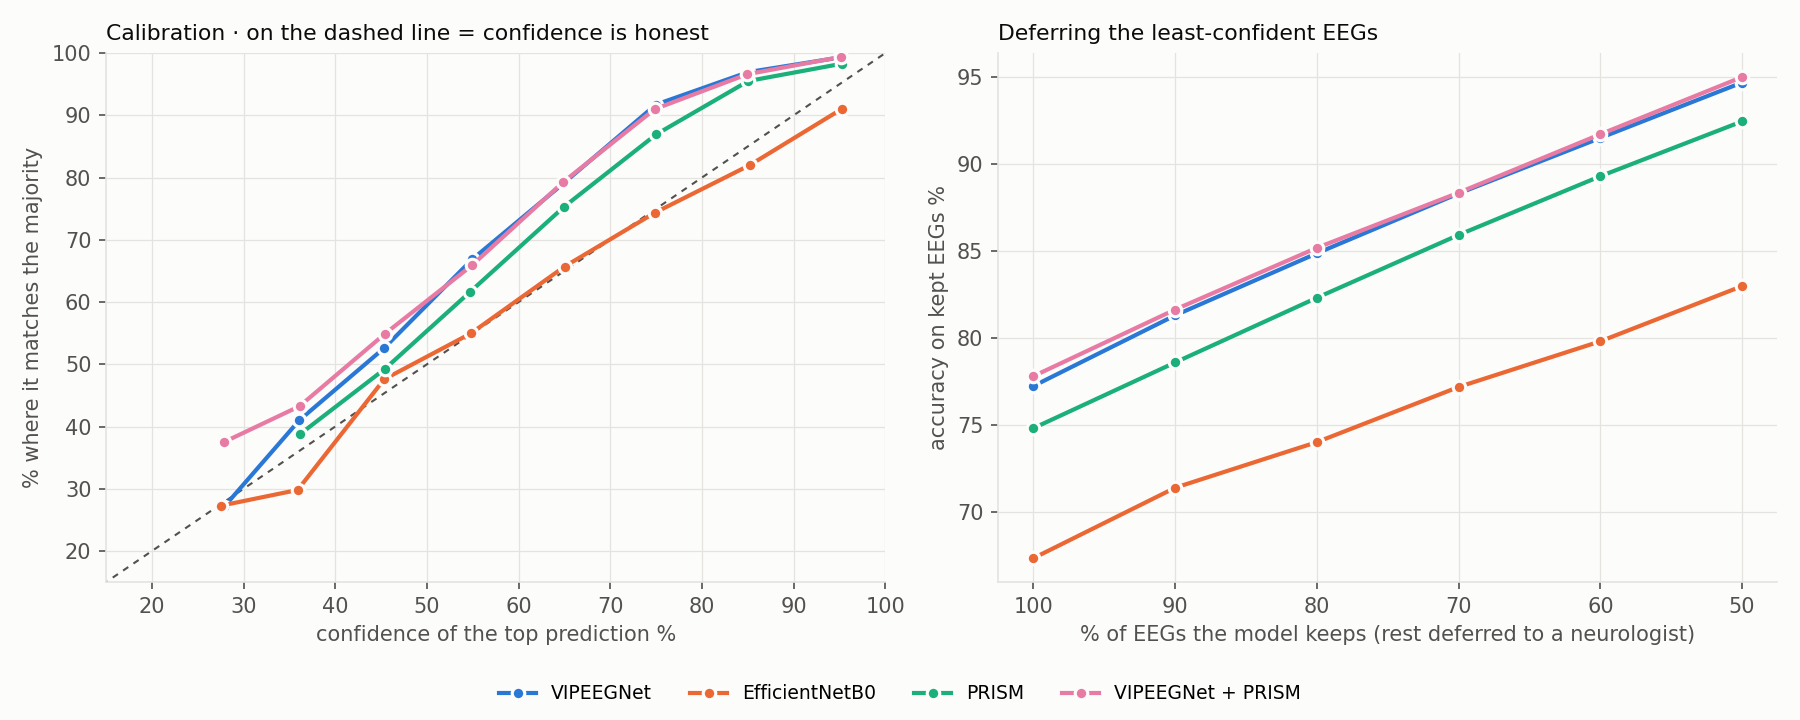

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
bins = np.linspace(0, 1, 11)
axs[0].plot([0, 100], [0, 100], color=INK2, lw=1, ls=(0, (3, 3)))
for n, p in preds.items():
    conf = p.max(1); ok = RIGHT[n]; idx = np.minimum(np.digitize(conf, bins) - 1, 9)
    pts = [(conf[idx == i].mean() * 100, ok[idx == i].mean() * 100) for i in range(10) if (idx == i).sum() >= 30]
    axs[0].plot(*zip(*pts), '-o', lw=2, ms=6, color=COL[n], mec=SURF, mew=1.5, label=n)
axs[0].set_xlabel('confidence of the top prediction %'); axs[0].set_ylabel('% where it matches the majority')
axs[0].set_title('Calibration · on the dashed line = confidence is honest', loc='left', fontsize=10.5, color=INK)
axs[0].set_xlim(15, 100); axs[0].set_ylim(15, 100)
for n in NAMES:
    s = E7c[E7c.model == n].sort_values('coverage %')
    axs[1].plot(s['coverage %'], s['accuracy %'], '-o', lw=2, ms=6, color=COL[n], mec=SURF, mew=1.5)
axs[1].invert_xaxis(); axs[1].set_xlabel('% of EEGs the model keeps (rest deferred to a neurologist)')
axs[1].set_ylabel('accuracy on kept EEGs %')
axs[1].set_title('Deferring the least-confident EEGs', loc='left', fontsize=10.5, color=INK)
legend_below(fig, axs[0], len(NAMES)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig4_calibration_deferral.png')

## 8. Model vs expert raters
For every EEG, one expert vote is held out; the remaining experts' majority is the reference (ties shared). An expert's
score = how often their vote matches the others' majority. The model is scored against **exactly the same references**,
so the two numbers are directly comparable: a model above the expert line agrees with the panel more than a typical single expert does.

In [15]:
def loo_agreement(votes, pred):
    """Expected agreement with the majority of the other raters, for (a) a random expert and (b) the model."""
    e_ag = np.zeros(len(votes)); m_ag = np.zeros(len(votes))
    for i, v in enumerate(votes):
        n = v.sum()
        for c in np.nonzero(v)[0]:
            r = v.copy(); r[c] -= 1; top = np.flatnonzero(r == r.max()); w = v[c] / n
            e_ag[i] += w * (c in top) / len(top)
            m_ag[i] += w * (pred[i] in top) / len(top)
    return e_ag, m_ag
rows, cls_rows = [], []
for n in NAMES:
    e_ag, m_ag = loo_agreement(VOTES, PRED[n])
    top2 = (np.argsort(-preds[n], 1)[:, :2] == Y[:, None]).any(1)
    rows.append({'model': n, 'model agreement % (LOO)': m_ag.mean() * 100, 'expert agreement % (LOO)': e_ag.mean() * 100,
                 'model - expert (points)': (m_ag.mean() - e_ag.mean()) * 100,
                 'accuracy vs full majority %': RIGHT[n].mean() * 100, 'top-2 accuracy %': top2.mean() * 100,
                 "Cohen's kappa vs majority": cohen_kappa_score(Y, PRED[n])})
    for c in range(6):
        mk = Y == c
        cls_rows.append({'model': n, 'class': CLASS[c], 'model %': m_ag[mk].mean() * 100, 'expert %': e_ag[mk].mean() * 100})
E8 = pd.DataFrame(rows).set_index('model'); E8c = pd.DataFrame(cls_rows)
E8.to_csv(f'{OUTD}/e8_model_vs_experts.csv'); E8c.to_csv(f'{OUTD}/e8_model_vs_experts_per_class.csv', index=False)
SCORE['8 agreement with expert panel % (higher better)'] = E8['model agreement % (LOO)']
display(E8.round(3))
t = E8c.pivot(index='class', columns='model', values='model %').loc[CLASS, NAMES]
t.insert(0, 'single expert', E8c[E8c.model == REF].set_index('class').loc[CLASS, 'expert %'])
print('Agreement with the other experts\' majority, by majority class (%)'); display(t.round(1))

,model agreement % (LOO),expert agreement % (LOO),model - expert (points),accuracy vs full majority %,top-2 accuracy %,Cohen's kappa vs majority
model,,,,,,
VIPEEGNet,77.846,67.083,10.763,77.244,94.283,0.655
EfficientNetB0,67.132,67.083,0.049,67.339,87.323,0.539
PRISM,75.419,67.083,8.336,74.819,92.000,0.614
VIPEEGNet + PRISM,78.362,67.083,11.279,77.811,94.205,0.661


Agreement with the other experts' majority, by majority class (%)


model,single expert,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
class,,,,,
Seizure,51.0,60.6,76.3,57.7,61.2
LPD,65.3,75.9,62.4,71.1,75.2
GPD,65.1,78.2,70.4,71.7,77.7
LRDA,43.7,43.7,26.2,33.7,43.4
GRDA,47.3,47.7,52.9,48.6,48.2
Other,75.2,88.2,74.1,88.3,89.6


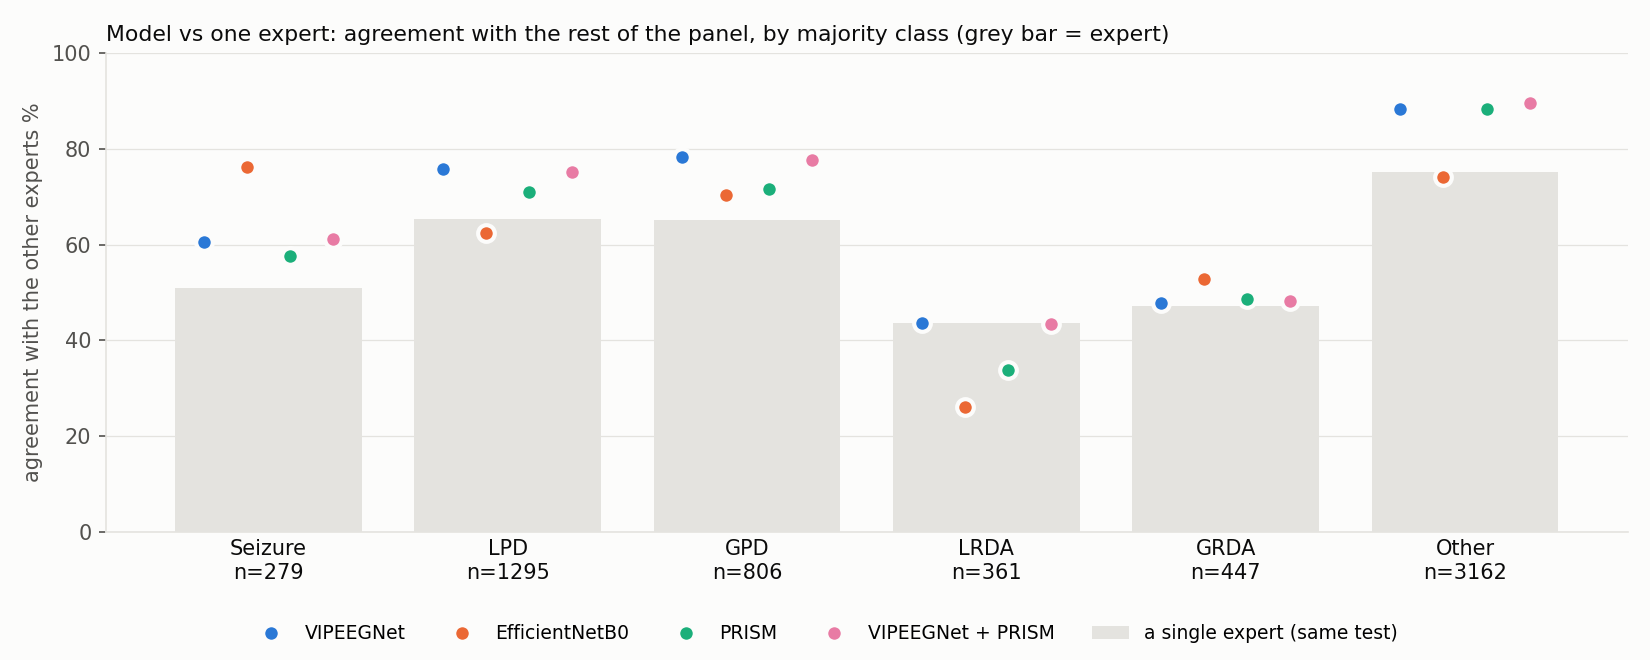

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(6); off = np.linspace(-0.27, 0.27, len(NAMES))
ex = t['single expert'].values
ax.bar(x, ex, width=0.78, color=GRID, edgecolor='none', label='a single expert (same test)', zorder=1)
for o, n in zip(off, NAMES):
    ax.plot(x + o, t[n].values, 'o', ms=8, color=COL[n], mec=SURF, mew=2, label=n, zorder=3)
ax.set_xticks(x, [f'{c}\nn={OH[:, i].sum()}' for i, c in enumerate(CLASS)]); ax.tick_params(axis='x', colors=INK, length=0)
ax.set_ylabel('agreement with the other experts %'); ax.set_ylim(0, 100); ax.grid(axis='x', visible=False)
ax.set_title('Model vs one expert: agreement with the rest of the panel, by majority class (grey bar = expert)',
             loc='left', fontsize=10.5, color=INK)
legend_below(fig, ax, len(NAMES) + 1); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig5_model_vs_experts.png')

## 9. Difficulty and ambiguity — does the model fail where experts disagree, and does it know?

In [17]:
share = yt.max(1)
ab = pd.cut(share, [0, 0.5, 0.75, 0.9999, 1.01], labels=['split (<50%)', 'majority (50-75%)', 'strong (75-<100%)', 'unanimous'])
vb = pd.cut(NV, [10, 13, 16, 20, 1000], right=False, labels=['10-12', '13-15', '16-19', '20+'])
def H(p): p = np.clip(p, 1e-7, 1); return -(p * np.log(p)).sum(1)
rows = []
for n, p in preds.items():
    for kind, b in (('expert agreement', ab), ('number of votes', vb)):
        g = pd.DataFrame({'b': b, 'k': K[n], 'ok': RIGHT[n]}).groupby('b', observed=True)
        for lev, s in g: rows.append({'model': n, 'grouping': kind, 'level': lev, 'n': len(s), 'KLD': s.k.mean(), 'accuracy %': s.ok.mean() * 100})
E9 = pd.DataFrame(rows)
E9u = pd.DataFrame({n: {'Spearman(model entropy, expert entropy)': spearmanr(H(p), H(yt))[0],
                        'mean model entropy': H(p).mean(), 'mean expert entropy': H(yt).mean()} for n, p in preds.items()}).T
E9.to_csv(f'{OUTD}/e9_difficulty.csv', index=False); E9u.to_csv(f'{OUTD}/e9_uncertainty_awareness.csv')
SCORE['9 KLD on split-vote EEGs (lower better)'] = E9[(E9.grouping == 'expert agreement') & (E9.level == 'split (<50%)')].set_index('model').KLD
for kind in ('expert agreement', 'number of votes'):
    s = E9[E9.grouping == kind]
    for col in ('KLD', 'accuracy %'):
        print(kind, '-', col); display(s.pivot_table(index=['level', 'n'], columns='model', values=col, observed=True, sort=False)[NAMES].round(4))
print('Does the model know which EEGs are ambiguous? (higher Spearman = better)'); display(E9u.loc[NAMES].round(3))

expert agreement - KLD


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
split (<50%),1291,0.2791,0.5852,0.3455,0.2745
majority (50-75%),2310,0.2513,0.5305,0.3063,0.2474
strong (75-<100%),1878,0.1978,0.3925,0.2353,0.1929
unanimous,871,0.1094,0.2679,0.1603,0.1083


expert agreement - accuracy %


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
split (<50%),1291,44.6940,40.5887,41.9830,46.3207
majority (50-75%),2310,72.5108,59.8701,70.0000,72.6407
strong (75-<100%),1878,95.1012,83.2268,92.5453,95.6869
unanimous,871,99.5408,92.5373,98.0482,99.6556


number of votes - KLD


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
10-12,1226,0.2597,0.5469,0.3067,0.2559
13-15,3446,0.2198,0.4431,0.2787,0.2166
16-19,1370,0.2055,0.4683,0.2498,0.2000
20+,308,0.1636,0.3650,0.1836,0.1570


number of votes - accuracy %


,model,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM
level,n,,,,
10-12,1226,70.9625,57.3409,68.5155,71.3703
13-15,3446,76.7847,68.4852,74.2890,77.3070
16-19,1370,79.3431,69.1241,76.5693,80.2920
20+,308,98.0519,86.3636,98.0519,98.0519


Does the model know which EEGs are ambiguous? (higher Spearman = better)


,"Spearman(model entropy, expert entropy)",mean model entropy,mean expert entropy
VIPEEGNet,0.733,0.847,0.653
EfficientNetB0,0.525,0.837,0.653
PRISM,0.687,0.843,0.653
VIPEEGNet + PRISM,0.738,0.846,0.653


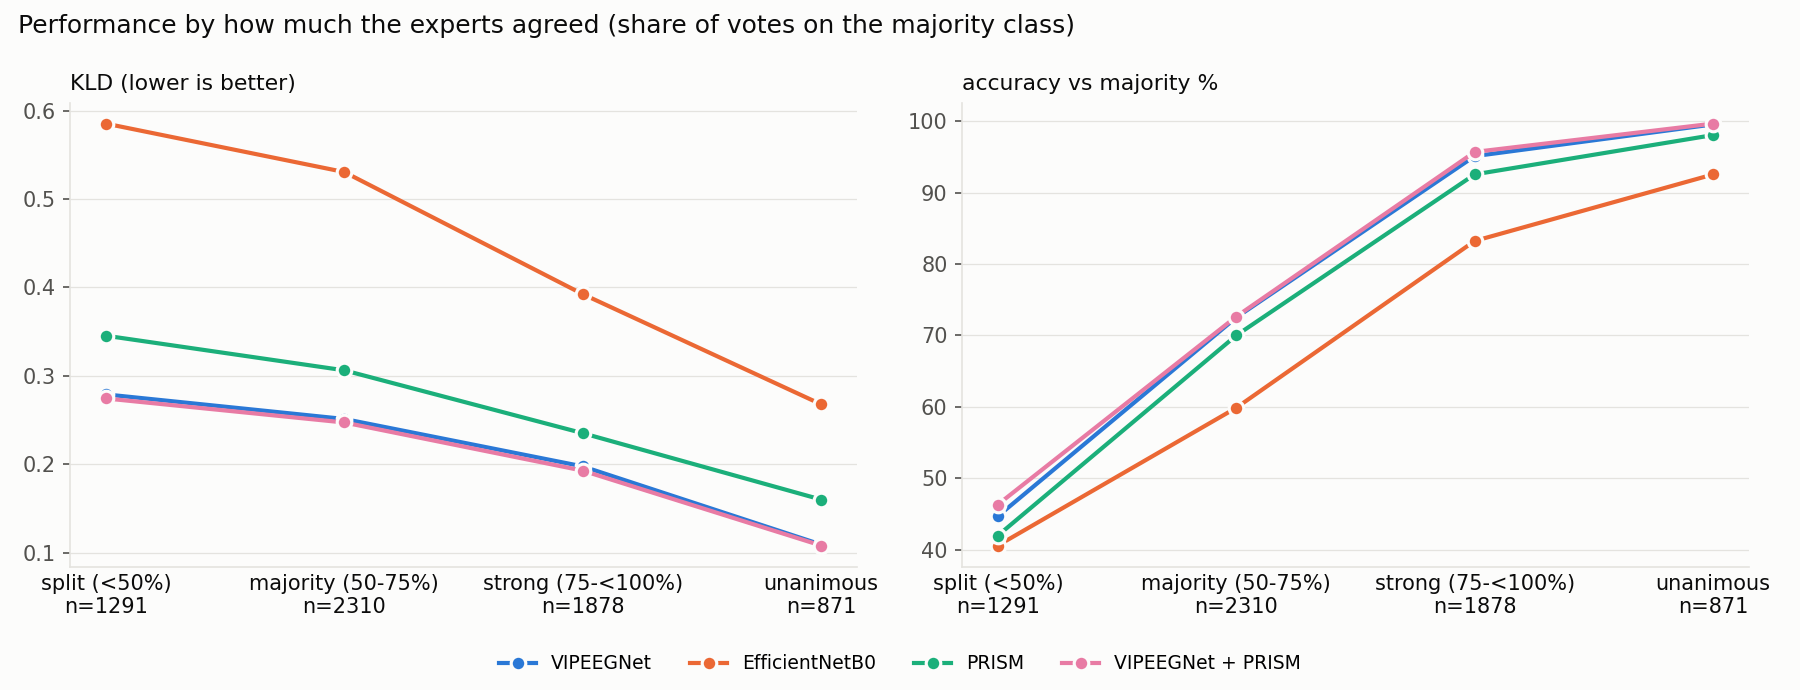

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
s = E9[E9.grouping == 'expert agreement']; levels = list(ab.categories); xx = np.arange(len(levels))
ns = s[s.model == REF].set_index('level').loc[levels, 'n'].values
for ax, col, lab in ((axs[0], 'KLD', 'KLD (lower is better)'), (axs[1], 'accuracy %', 'accuracy vs majority %')):
    for n in NAMES:
        v = s[s.model == n].set_index('level').loc[levels, col].values
        ax.plot(xx, v, '-o', lw=2, ms=7, color=COL[n], mec=SURF, mew=1.5, label=n)
    ax.set_xticks(xx, [f'{l}\nn={k}' for l, k in zip(levels, ns)]); ax.tick_params(axis='x', colors=INK, length=0)
    ax.set_title(lab, loc='left', fontsize=10.5, color=INK); ax.grid(axis='x', visible=False)
fig.suptitle('Performance by how much the experts agreed (share of votes on the majority class)', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(NAMES)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig6_by_expert_agreement.png')

## 10. Robustness and complementarity
- **Folds:** each model scored on its own folds — mean, spread, worst fold.
- **Patients:** mean KLD per patient — median, 90th percentile, worst patient, share of patients above 0.5.
- **Pairs:** McNemar exact test on right/wrong top predictions (ignores patient clustering — read the p-value as indicative), rate where both are wrong, and the "oracle" rate where at least one is right.

In [19]:
rows = []
for n in NAMES:
    fk = pd.Series(K[n]).groupby(folds[n]).mean(); pk = pd.Series(K[n]).groupby(inv).mean()
    rows.append({'model': n, 'fold mean': fk.mean(), 'fold std': fk.std(), 'worst fold': fk.max(), 'best fold': fk.min(),
                 'patient median': pk.median(), 'patient 90th pct': pk.quantile(0.9), 'worst patient': pk.max(),
                 '% patients KLD > 0.5': (pk > 0.5).mean() * 100})
E10 = pd.DataFrame(rows).set_index('model')
pairs = []
for i, a in enumerate(NAMES):
    for b in NAMES[i + 1:]:
        ra, rb = RIGHT[a], RIGHT[b]; x1, x2 = int((ra & ~rb).sum()), int((~ra & rb).sum())
        pairs.append({'pair': f'{a} vs {b}', f'only first right': x1, 'only second right': x2,
                      'McNemar p': binomtest(min(x1, x2), x1 + x2, 0.5).pvalue if x1 + x2 else 1.0,
                      'both wrong %': (~ra & ~rb).mean() * 100, 'at least one right %': (ra | rb).mean() * 100,
                      'KLD error correlation': np.corrcoef(K[a], K[b])[0, 1]})
E10p = pd.DataFrame(pairs)
E10.to_csv(f'{OUTD}/e10_robustness.csv'); E10p.to_csv(f'{OUTD}/e10_pairwise.csv', index=False)
SCORE['10 worst-decile patient KLD (lower better)'] = E10['patient 90th pct']
display(E10.round(4)); display(E10p.round(4))

,fold mean,fold std,worst fold,best fold,patient median,patient 90th pct,worst patient,% patients KLD > 0.5
model,,,,,,,,
VIPEEGNet,0.2221,0.0070,0.2319,0.2142,0.1740,0.3950,2.8426,5.3622
EfficientNetB0,0.4630,0.0330,0.5117,0.4282,0.3585,1.0244,3.7297,33.3960
PRISM,0.2737,0.0115,0.2854,0.2590,0.2120,0.4783,2.9444,9.3133
VIPEEGNet + PRISM,0.2181,0.0074,0.2285,0.2089,0.1696,0.3805,2.8621,4.8918


,pair,only first right,only second right,McNemar p,both wrong %,at least one right %,KLD error correlation
0,VIPEEGNet vs EfficientNetB0,1068,439,0.0000,15.8425,84.1575,0.4099
1,VIPEEGNet vs PRISM,476,322,0.0000,17.6850,82.3150,0.6764
2,VIPEEGNet vs VIPEEGNet + PRISM,79,115,0.0118,20.9449,79.0551,0.9868
3,EfficientNetB0 vs PRISM,533,1008,0.0000,16.7874,83.2126,0.3903
4,EfficientNetB0 vs VIPEEGNet + PRISM,409,1074,0.0000,15.7480,84.2520,0.4247
5,PRISM vs VIPEEGNet + PRISM,219,409,0.0000,18.7402,81.2598,0.7608


## Scorecard — one headline number per evaluation

In [20]:
sc = pd.DataFrame(SCORE).T[NAMES]
lower = sc.index.str.contains('lower')
sc['best'] = [r.idxmin() if lw else r.idxmax() for (_, r), lw in zip(sc[NAMES].iterrows(), lower)]
sc.to_csv(f'{OUTD}/scorecard.csv')
print('Wins per model:', sc.best.value_counts().to_dict())
sc.round(4)

Wins per model: {'VIPEEGNet + PRISM': 10, 'VIPEEGNet': 1}


,VIPEEGNet,EfficientNetB0,PRISM,VIPEEGNet + PRISM,best
1 KLD (lower better),0.2217,0.4648,0.2732,0.2177,VIPEEGNet + PRISM
2 macro-F1 % (higher better),66.2628,55.5827,62.5268,66.9880,VIPEEGNet + PRISM
3 macro-AUPRC (higher better),0.7589,0.5936,0.6977,0.7633,VIPEEGNet + PRISM
4 harmful-vs-Other AUROC (higher better),0.9291,0.8741,0.9125,0.9307,VIPEEGNet + PRISM
"5 errors per 1,000 EEGs (lower better)",227.5591,326.6142,251.8110,221.8898,VIPEEGNet + PRISM
"5b seizure errors per 1,000 EEGs, missed + false alarms (lower better)",30.8661,96.8504,36.3780,30.3937,VIPEEGNet + PRISM
6 seizure specificity % at 90% sensitivity (higher better),92.8677,85.8508,90.8088,93.2960,VIPEEGNet + PRISM
7 class-wise ECE vs vote shares (lower better),0.0061,0.0448,0.0149,0.0074,VIPEEGNet
8 agreement with expert panel % (higher better),77.8464,67.1320,75.4195,78.3622,VIPEEGNet + PRISM
9 KLD on split-vote EEGs (lower better),0.2791,0.5852,0.3455,0.2745,VIPEEGNet + PRISM


In [21]:
def mdt(df):
    try: return df.round(4).to_markdown()
    except ImportError: return '```\n' + df.round(4).to_string() + '\n```'
piv = lambda d, i, c, v, order: d.pivot(index=i, columns=c, values=v).loc[order, NAMES]
rep = [f'# HMS — ten evaluations of four models ({pd.Timestamp.today().date()})',
       f'{N:,} EEG rows with >=10 votes, {NP:,} patients. Reference: {REF}. 95% CIs resample patients.',
       '## Scorecard', mdt(sc),
       '## 1. Distribution fit', mdt(E1),
       '## 2. False negatives per class (count)', mdt(piv(E2, 'class', 'model', 'FN', CLASS)),
       '## 2. False positives per class (count)', mdt(piv(E2, 'class', 'model', 'FP', CLASS)),
       '## 3. AUPRC per class', mdt(piv(E3, 'class', 'model', 'AUPRC', CLASS)),
       '## 4. Clinical decision tasks', mdt(E4.set_index(['task', 'model'])),
       '## 5. Error types per 1,000 EEGs', mdt(piv(E5, 'error type', 'model', 'per 1,000 EEGs', TYPES + ['all errors'])),
       '## 6. Specificity % at 90% sensitivity', mdt(piv(E6, 'target', 'model', 'specificity % at 90% sensitivity', CLASS + ['Harmful (any IIIC)'])),
       '## 7. Calibration', mdt(E7), '## 7. Accuracy % when deferring', mdt(E7c.pivot(index='coverage %', columns='model', values='accuracy %')[NAMES]),
       '## 8. Model vs experts', mdt(E8), mdt(t),
       '## 9. Uncertainty awareness', mdt(E9u),
       '## 10. Robustness', mdt(E10), mdt(E10p.set_index('pair')),
       '\n'.join(f'![{f}]({f})' for f in sorted(x for x in os.listdir(OUTD) if x.endswith('.png')))]
open(f'{OUTD}/report.md', 'w').write('\n\n'.join(rep))
json.dump({'models': MODELS, 'n_rows': int(N), 'n_patients': int(NP), 'scorecard': sc.reset_index().to_dict('records')},
          open(f'{OUTD}/summary.json', 'w'), indent=2, default=str)
print('saved to', OUTD); print(sorted(os.listdir(OUTD)))

saved to /home/nfs/jhb-dehzangi/ws04/gs1147/hms/results/comparisons/top10_eval
['e10_pairwise.csv', 'e10_robustness.csv', 'e1_distribution_fit.csv', 'e2_confusion_counts_EfficientNetB0.csv', 'e2_confusion_counts_PRISM.csv', 'e2_confusion_counts_VIPEEGNet.csv', 'e2_confusion_counts_VIPEEGNet_plus_PRISM.csv', 'e2_fp_fn_per_class.csv', 'e3_auroc_auprc.csv', 'e4_clinical_tasks.csv', 'e5_error_types.csv', 'e6_operating_points.csv', 'e7_calibration.csv', 'e7_selective_prediction.csv', 'e8_model_vs_experts.csv', 'e8_model_vs_experts_per_class.csv', 'e9_difficulty.csv', 'e9_uncertainty_awareness.csv', 'fig1_fp_fn.png', 'fig2_error_types.png', 'fig3_roc_operating_points.png', 'fig4_calibration_deferral.png', 'fig5_model_vs_experts.png', 'fig6_by_expert_agreement.png', 'report.md', 'scorecard.csv', 'summary.json']
